In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("/content/hospital_appointment_no_show_practice.csv")
print(df.head())

  Patient_ID   Age  Gender        Department Appointment_Date Scheduled_Date  \
0      P1001  74.0    Male       Orthopedics       2025-04-22     2025-04-07   
1      P1002  74.0    Male        Cardiology       2025-06-17     2025-06-03   
2      P1003  55.0  Female       Orthopedics       2025-01-10     2024-12-13   
3      P1004  52.0  Female  General Medicine       2025-03-13     2025-03-12   
4      P1005  76.0  Female  General Medicine       2025-04-08     2025-04-02   

  Appointment_Type SMS_Reminder Attendance_Status  
0              New          Yes          Attended  
1        Follow-up          Yes          Attended  
2              New          NaN           No-show  
3        Follow-up           No          Attended  
4        Follow-up           No          Attended  


In [ ]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Department', 'Appointment_Date',
       'Scheduled_Date', 'Appointment_Type', 'SMS_Reminder',
       'Attendance_Status'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         600 non-null    object 
 1   Age                580 non-null    float64
 2   Gender             592 non-null    object 
 3   Department         583 non-null    object 
 4   Appointment_Date   600 non-null    object 
 5   Scheduled_Date     579 non-null    object 
 6   Appointment_Type   591 non-null    object 
 7   SMS_Reminder       567 non-null    object 
 8   Attendance_Status  600 non-null    object 
dtypes: float64(1), object(8)
memory usage: 42.3+ KB


In [ ]:
df.describe()

,Age
count,580.000000
mean,52.051724
std,19.685632
min,18.000000
25%,35.000000
50%,52.500000
75%,68.250000
max,85.000000


In [ ]:
df_clean = df.drop_duplicates()

In [ ]:
df_clean.isnull().sum()

,0
Patient_ID,0
Age,20
Gender,8
Department,17
Appointment_Date,0
Scheduled_Date,21
Appointment_Type,9
SMS_Reminder,33
Attendance_Status,0


In [ ]:
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

In [ ]:
catagorical_cols = [
    "Gender",
    "Department",
    "Appointment_Type",
    "SMS_Reminder"
]

for cols in catagorical_cols:
  df_clean[cols] = df_clean[cols].fillna("Unknown")

In [ ]:
df_clean.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
Department,0
Appointment_Date,0
Scheduled_Date,21
Appointment_Type,0
SMS_Reminder,0
Attendance_Status,0


In [ ]:
df_clean['Appointment_Date'] = pd.to_datetime(df_clean['Appointment_Date'], errors="coerce")
df_clean['Scheduled_Date'] = pd.to_datetime(df_clean['Scheduled_Date'], errors="coerce")

df_clean.dtypes

,0
Patient_ID,object
Age,float64
Gender,object
Department,object
Appointment_Date,datetime64[ns]
Scheduled_Date,datetime64[ns]
Appointment_Type,object
SMS_Reminder,object
Attendance_Status,object


In [ ]:
df_clean["Waiting_Days"] = (df_clean['Appointment_Date'] - df_clean['Scheduled_Date']).dt.days
df_clean["Waiting_Days"].head()

,Waiting_Days
0,15.0
1,14.0
2,28.0
3,1.0
4,6.0


In [ ]:
df_clean["Waiting_Days"].isnull().sum()

np.int64(21)

In [ ]:
total_appointments = len(df_clean)

attendance_counts = df_clean["Attendance_Status"].value_counts()

attended = attendance_counts.get("Attended", 0)
no_shows = attendance_counts.get("No-show", 0)

attendance_rate = (attended/total_appointments) * 100
no_show_rate = (no_shows/total_appointments) * 100

print("Total Appointments:", total_appointments)
print("Attended Appointments:", attended)
print("No-Show Appointments:", no_shows)
print(f"Attendance Rate: {attendance_rate:.2f}%")
print(f"No-Show Rate: {no_show_rate:.2f}%")

Total Appointments: 600
Attended Appointments: 476
No-Show Appointments: 124
Attendance Rate: 79.33%
No-Show Rate: 20.67%


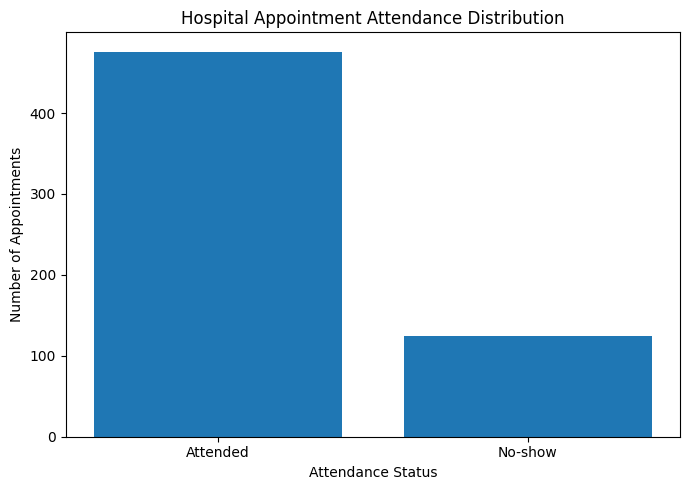

In [ ]:
status_count = df_clean['Attendance_Status'].value_counts()

plt.figure(figsize=(7,5))
plt.bar(status_count.index, status_count.values)

plt.title("Hospital Appointment Attendance Distribution")
plt.xlabel("Attendance Status")
plt.ylabel("Number of Appointments")
plt.tight_layout()
plt.show()

In [15]:
total = df_clean.groupby("Department")["Attendance_Status"].count()

no_show = df_clean[df_clean['Attendance_Status'] == "No-show"].groupby("Department").size()

no_show_rate = (no_show / total) * 100

department_analysis = pd.DataFrame({
    "Total Attendance": total,
    "No-Show": no_show,
    "No-Show-Rate": no_show_rate
})

display(department_analysis.round(2))

,Total Attendance,No-Show,No-Show-Rate
Department,,,
Cardiology,69,22,31.88
Dermatology,103,21,20.39
General Medicine,216,38,17.59
Orthopedics,104,24,23.08
Pediatrics,91,16,17.58
Unknown,17,3,17.65


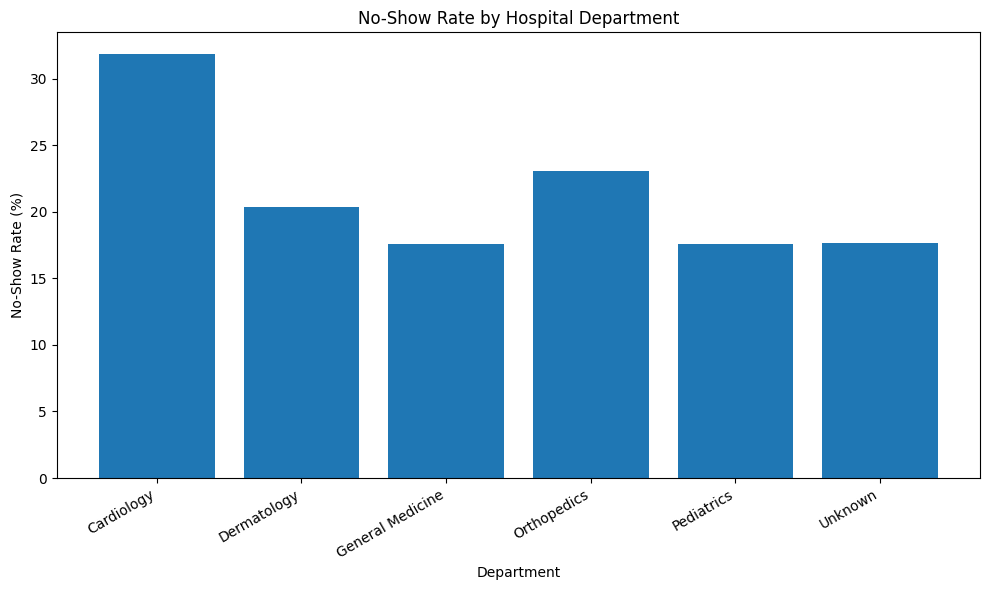

In [16]:
plt.figure(figsize=(10,6))

plt.bar(department_analysis.index, department_analysis["No-Show-Rate"])

plt.title("No-Show Rate by Hospital Department")
plt.xlabel("Department")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [17]:
sms_analysis = df_clean.groupby("SMS_Reminder")["Attendance_Status"].value_counts().unstack(fill_value=0)
display(sms_analysis)

Attendance_Status,Attended,No-show
SMS_Reminder,,
No,180,42
Unknown,22,11
Yes,274,71


In [21]:
total = sms_analysis["Attended"] + sms_analysis["No-show"]

sms_analysis["No_Show_Rate"] = (sms_analysis['No-show'] / total) * 100

display(sms_analysis.round(2))

Attendance_Status,Attended,No-show,No_Show_Rate
SMS_Reminder,,,
No,180,42,18.92
Unknown,22,11,33.33
Yes,274,71,20.58


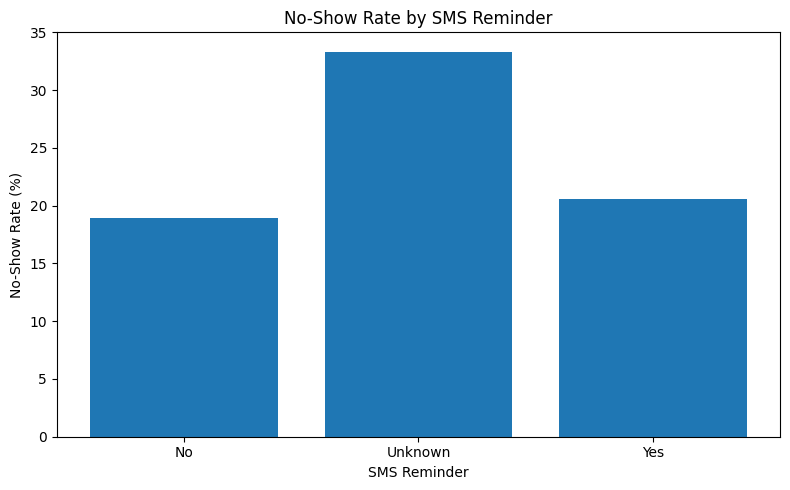

In [22]:
plt.figure(figsize=(8,5))

plt.bar(sms_analysis.index, sms_analysis['No_Show_Rate'])

plt.title("No-Show Rate by SMS Reminder")
plt.xlabel("SMS Reminder")
plt.ylabel("No-Show Rate (%)")
plt.tight_layout()
plt.show()

In [23]:
waiting_analysis = df_clean.groupby("Attendance_Status")["Waiting_Days"].mean()
display(waiting_analysis.round(2))

,Waiting_Days
Attendance_Status,
Attended,12.49
No-show,15.28


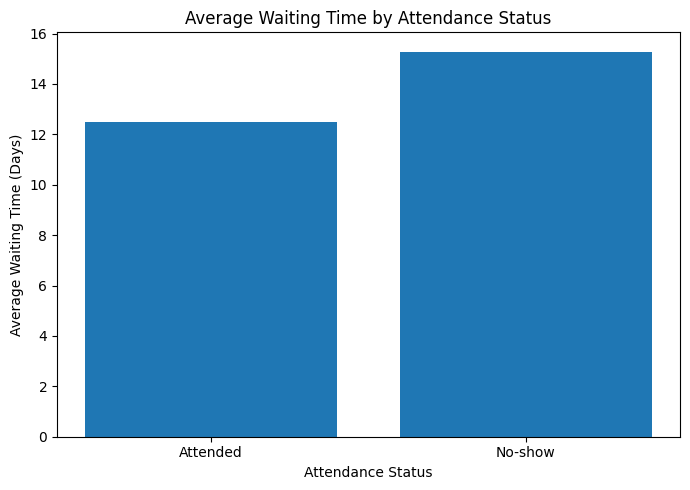

In [24]:
plt.figure(figsize=(7,5))

plt.bar(waiting_analysis.index, waiting_analysis.values)

plt.title("Average Waiting Time by Attendance Status")
plt.xlabel("Attendance Status")
plt.ylabel("Average Waiting Time (Days)")
plt.tight_layout()
plt.show()

In [25]:
age_analysis = df_clean.groupby("Attendance_Status")["Age"].mean()

display(age_analysis.round(2))

,Age
Attendance_Status,
Attended,51.93
No-show,52.59


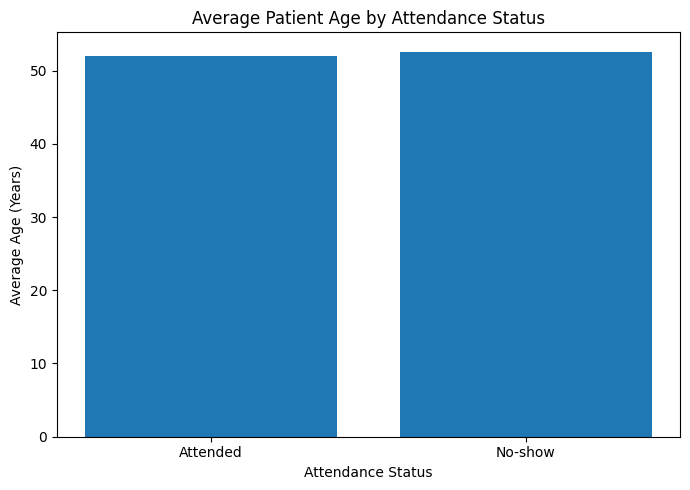

In [26]:
plt.figure(figsize=(7,5))

plt.bar(age_analysis.index, age_analysis.values)

plt.title("Average Patient Age by Attendance Status")
plt.xlabel("Attendance Status")
plt.ylabel("Average Age (Years)")
plt.tight_layout()
plt.show()